# Heart Health Information Assistant

In [1]:
import re
import math
import random
from collections import Counter, defaultdict

### Labelled Corpus

In [2]:
corpus = {
    "coronary_artery_disease": [
        "What happens when the heart arteries become blocked?",
        "Can plaque buildup affect blood supply to the heart?",
        "Why do coronary arteries become narrow?",
        "What is the role of arteries in coronary disease?",
        "Can reduced blood flow damage heart muscles?",
        "How does a person develop coronary artery problems?"
    ],
    "heart_failure": [
        "Why does the heart become too weak to pump blood?",
        "Can fluid accumulate in the body due to heart problems?",
        "What happens when the heart cannot pump enough blood?",
        "Why do people with weak hearts experience fatigue?",
        "How does reduced pumping ability affect the body?",
        "What lifestyle changes help people manage heart failure?"
    ],
    "chest_pain": [
        "I feel a squeezing sensation around my chest.",
        "What could cause discomfort near the breastbone?",
        "Why does my chest feel tight sometimes?",
        "Can indigestion feel similar to cardiac pain?",
        "What does pressure in the chest indicate?",
        "Why do I experience pain in the upper chest area?"
    ],
    "breathing_difficulty": [
        "I get out of breath after climbing a few stairs.",
        "Why is it difficult to breathe when lying down?",
        "I feel like I cannot get enough air.",
        "Can poor heart function make breathing harder?",
        "Why do I wake up feeling breathless?",
        "What causes unusual breathlessness during physical activity?"
    ],
    "high_blood_pressure": [
        "My blood pressure readings are consistently elevated.",
        "What lifestyle habits contribute to hypertension?",
        "Can excessive salt consumption raise blood pressure?",
        "Why is uncontrolled hypertension dangerous?",
        "What habits can help maintain normal BP levels?",
        "How does hypertension affect the cardiovascular system?"
    ],
    "high_cholesterol": [
        "What is the difference between LDL and HDL?",
        "Why is bad cholesterol harmful to the body?",
        "Can fatty deposits develop inside blood vessels?",
        "How can lifestyle changes improve lipid levels?",
        "What happens when LDL levels become too high?",
        "Which habits contribute to unhealthy cholesterol levels?"
    ],
    "diet": [
        "Are nuts beneficial for cardiovascular wellness?",
        "Should I reduce saturated fats in my meals?",
        "Which cooking oils are better for the heart?",
        "Is a Mediterranean-style diet good for cardiovascular health?",
        "How can I include more fibre in my daily meals?",
        "Why should people limit processed foods?"
    ],
    "exercise": [
        "Can cycling help improve cardiovascular fitness?",
        "Is swimming beneficial for strengthening the heart?",
        "How does physical activity affect heart efficiency?",
        "What are some beginner-friendly aerobic activities?",
        "Can sitting for long hours affect heart health?",
        "How often should adults participate in physical activity?"
    ],
    "diagnosis": [
        "How does an echocardiography scan work?",
        "Can an ECG identify irregular heart rhythms?",
        "What information does a cardiac MRI provide?",
        "Why is a treadmill test performed?",
        "How do doctors measure the electrical activity of the heart?",
        "What is the purpose of a cholesterol blood test?"
    ],
    "medication": [
        "What is the function of beta blockers?",
        "Why are statin drugs recommended to some patients?",
        "Do prescribed cardiac drugs require regular monitoring?",
        "What should patients know before taking heart medicines?",
        "Why should blood pressure medication be taken as prescribed?",
        "What are common precautions associated with cardiac medicines?"
    ]
}

In [3]:
print("Total categories:", len(corpus))
ans=sum(len(q) for q in corpus.values())
print("Total queries:", ans)

Total categories: 10
Total queries: 60


### Taxonomy

In [4]:
dataset = []
for intent, queries in corpus.items():
    for query in queries:
        dataset.append((query,intent))
for query, intent in dataset[:10]:
    print("Query:", query)
    print("Intent:", intent)
    print()

Query: What happens when the heart arteries become blocked?
Intent: coronary_artery_disease

Query: Can plaque buildup affect blood supply to the heart?
Intent: coronary_artery_disease

Query: Why do coronary arteries become narrow?
Intent: coronary_artery_disease

Query: What is the role of arteries in coronary disease?
Intent: coronary_artery_disease

Query: Can reduced blood flow damage heart muscles?
Intent: coronary_artery_disease

Query: How does a person develop coronary artery problems?
Intent: coronary_artery_disease

Query: Why does the heart become too weak to pump blood?
Intent: heart_failure

Query: Can fluid accumulate in the body due to heart problems?
Intent: heart_failure

Query: What happens when the heart cannot pump enough blood?
Intent: heart_failure

Query: Why do people with weak hearts experience fatigue?
Intent: heart_failure



In [5]:
taxonomy = {
    "Heart Diseases": {
        "Coronary Artery Disease": "coronary_artery_disease",
        "Heart Failure": "heart_failure"
    },

    "Symptoms": {
        "Chest Pain": "chest_pain",
        "Breathing Difficulty": "breathing_difficulty"
    },

    "Risk Factors": {
        "High Blood Pressure": "high_blood_pressure",
        "High Cholesterol": "high_cholesterol"
    },

    "Prevention": {
        "Diet and Nutrition": "diet",
        "Exercise and Lifestyle": "exercise"
    },

    "Heart Health Management": {
        "Diagnosis and Tests": "diagnosis",
        "Medication Information": "medication"
    }
}

### Ontology

In [6]:
domain = [
    "Heart",
    "Blood",
    "Arteries",
    "Blood Pressure",
    "Cholesterol",
    "Heart Disease",
    "ECG",
    "Exercise",
    "Diet",
    "Medication"
]

print("Domain:")
for concept in domain:
    print(concept)

print("Total Concepts:", len(domain))

Domain:
Heart
Blood
Arteries
Blood Pressure
Cholesterol
Heart Disease
ECG
Exercise
Diet
Medication
Total Concepts: 10


In [7]:
ontology = {
    "Heart": {
        "receives": "Blood",
        "pumps": "Blood"
    },
    "Blood": {
        "flows_through": "Arteries"
    },
    "Arteries": {
        "supply_blood_to": "Heart",
        "can_be_blocked_by": "Cholesterol"
    },
    "Blood Pressure": {
        "affects": "Heart",
        "can_be_increased_by": "High Sodium Intake"
    },
    "Cholesterol": {
        "can_accumulate_in": "Arteries",
        "high_levels_increase_risk_of": "Heart Disease"
    },
    "Heart Disease": {
        "may_cause": "Chest Pain"
    },
    "ECG": {
        "monitors": "Heart Activity"
    },
    "Exercise": {
        "improves": "Blood Circulation",
        "supports": "Heart Health"
    },
    "Diet": {
        "helps_control": "Cholesterol",
        "influences": "Heart Health"
    },
    "Medication": {
        "helps_manage": "Blood Pressure",
        "helps_control": "Cholesterol"
    }
}

In [8]:
def get_relationships(concept):
    if concept in ontology:
        print("Concept:", concept)
        for relation, target in ontology[concept].items():
            print(relation, "-->", target)
    else:
        print("Concept not found in ontology.")

get_relationships("Cholesterol")

Concept: Cholesterol
can_accumulate_in --> Arteries
high_levels_increase_risk_of --> Heart Disease


### NLP Preprocessing

In [9]:
def convert_lowercase(text):
    return text.lower()
    
query = "What are the Causes of Heart Diseases?"
print("Original:", query)
print("Lowercase:", convert_lowercase(query))

Original: What are the Causes of Heart Diseases?
Lowercase: what are the causes of heart diseases?


In [10]:
def tokenize(text):
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    return text.split()

query = "what are the causes of heart diseases?"
tokens = tokenize(query)
print("Tokens:", tokens)

Tokens: ['what', 'are', 'the', 'causes', 'of', 'heart', 'diseases']


In [11]:
stop_words = {
    "is", "the", "are", "of", "what", "how",
    "a", "an", "and", "or", "to", "in", "on",
    "for", "can", "does", "do", "my", "i",
    "me", "it", "with", "be", "was", "were",
    "why", "which", "who", "your", "you", "at",
    "by", "from", "about", "their", "this", "that"
}
def remove_stopwords(tokens):
    return [word for word in tokens if word not in stop_words]
filtered_tokens = remove_stopwords(tokens)
print("Before:", tokens)
print("After:", filtered_tokens)

Before: ['what', 'are', 'the', 'causes', 'of', 'heart', 'diseases']
After: ['causes', 'heart', 'diseases']


In [12]:
lemma_dictionary = {
    "diseases": "disease",
    "causes": "cause",
    "medicines": "medicine",
    "symptoms": "symptom",
    "arteries": "artery",
    "activities": "activity",
    "berries": "berry",
    "feet": "foot",
    "teeth": "tooth"
}
def lemmatize_word(word):
    if word in lemma_dictionary:
        return lemma_dictionary[word]
    if word.endswith("ies") and len(word) > 4:
        return word[:-3] + "y"
    if word.endswith("ing") and len(word) > 5:
        return word[:-3]
    if word.endswith("s") and not word.endswith("ss") and len(word) > 3:
        return word[:-1]
    return word

def lemmatize_tokens(tokens):
    return [lemmatize_word(word) for word in tokens]

final_tokens = lemmatize_tokens(filtered_tokens)
print("Before Lemmatization:", filtered_tokens)
print("After Lemmatization:", final_tokens)

Before Lemmatization: ['causes', 'heart', 'diseases']
After Lemmatization: ['cause', 'heart', 'disease']


In [13]:
def preprocess_text(text):
    text = convert_lowercase(text)
    tokens = tokenize(text)
    tokens = remove_stopwords(tokens)
    tokens = lemmatize_tokens(tokens)
    return tokens

query = "What are the Causes of Heart Diseases?"
processed_query = preprocess_text(query)
print("Original Query:", query)
print("Processed Query:", processed_query)

Original Query: What are the Causes of Heart Diseases?
Processed Query: ['cause', 'heart', 'disease']


In [14]:
processed_dataset = []
for query, intent in dataset:
    cleaned_query = preprocess_text(query)
    processed_dataset.append((cleaned_query, intent))

print("Total processed queries:", len(processed_dataset))
for item in processed_dataset[:5]:
    print(item)

Total processed queries: 60
(['happen', 'when', 'heart', 'artery', 'become', 'blocked'], 'coronary_artery_disease')
(['plaque', 'buildup', 'affect', 'blood', 'supply', 'heart'], 'coronary_artery_disease')
(['coronary', 'artery', 'become', 'narrow'], 'coronary_artery_disease')
(['role', 'artery', 'coronary', 'disease'], 'coronary_artery_disease')
(['reduced', 'blood', 'flow', 'damage', 'heart', 'muscle'], 'coronary_artery_disease')


### TF - IDF Feature Extraction

In [15]:
vocabulary = set()

for tokens, intent in processed_dataset:
    for word in tokens:
        vocabulary.add(word)
vocabulary = sorted(vocabulary)
print("Total unique words:", len(vocabulary))
print("\nVocabulary:")
print(vocabulary)

Total unique words: 191

Vocabulary:
['ability', 'accumulate', 'activity', 'adult', 'aerobic', 'affect', 'after', 'air', 'area', 'around', 'artery', 'as', 'associated', 'bad', 'become', 'before', 'beginnerfriendly', 'beneficial', 'beta', 'better', 'between', 'blocked', 'blocker', 'blood', 'body', 'bp', 'breastbone', 'breath', 'breathe', 'breathless', 'breathlessness', 'buildup', 'cannot', 'cardiac', 'cardiovascular', 'cause', 'change', 'chest', 'cholesterol', 'climb', 'common', 'consistently', 'consumption', 'contribute', 'cook', 'coronary', 'could', 'cycl', 'daily', 'damage', 'dangerou', 'deposit', 'develop', 'diet', 'difference', 'difficult', 'discomfort', 'disease', 'doctor', 'down', 'drug', 'due', 'dur', 'ecg', 'echocardiography', 'efficiency', 'electrical', 'elevated', 'enough', 'excessive', 'experience', 'failure', 'fat', 'fatigue', 'fatty', 'feel', 'few', 'fibre', 'fitness', 'flow', 'fluid', 'food', 'function', 'get', 'good', 'habit', 'happen', 'harder', 'harmful', 'hdl', 'healt

In [16]:
def calculate_tf(tokens):
    word_count = Counter(tokens)
    total_words = len(tokens)
    tf = {}
    for word, count in word_count.items():
        tf[word] = count / total_words

    return tf

In [17]:
def calculate_idf(documents, vocabulary):
    total_documents = len(documents)
    idf = {}
    for word in vocabulary:
        document_frequency = 0
        for tokens in documents:
            if word in tokens:
                document_frequency += 1
        idf[word] = math.log((total_documents + 1) / (document_frequency + 1)) + 1
    return idf

In [18]:
def calculate_tfidf(tokens, idf_values):
    tf_values = calculate_tf(tokens)
    tfidf_vector = {}
    for word in idf_values:
        tf = tf_values.get(word, 0)
        tfidf_vector[word] = tf * idf_values[word]

    return tfidf_vector

In [19]:
documents = [tokens for tokens, intent in processed_dataset]
idf_values = calculate_idf(documents, vocabulary)
print("Sample IDF values:\n")
for word in vocabulary[:10]:
    print(word, ":", round(idf_values[word], 4))

Sample IDF values:

ability : 4.4177
accumulate : 4.4177
activity : 3.3191
adult : 4.4177
aerobic : 4.4177
affect : 3.3191
after : 4.4177
air : 4.4177
area : 4.4177
around : 4.4177


In [20]:
tfidf_vectors = []
for tokens, intent in processed_dataset:
    vector = calculate_tfidf(tokens, idf_values)
    tfidf_vectors.append(vector)

print("Total TF-IDF vectors:", len(tfidf_vectors))
print("\nFirst query vector:")
for word, score in tfidf_vectors[0].items():
    if score > 0:
        print(word, ":", round(score, 4))

Total TF-IDF vectors: 60

First query vector:
artery : 0.5836
become : 0.5836
blocked : 0.7363
happen : 0.6208
heart : 0.3796
when : 0.5836


In [21]:
samples= []
for vector in tfidf_vectors:
    numerical_vector = [
        vector[word] for word in vocabulary
    ]
    samples.append(numerical_vector)
label= [intent for tokens, intent in processed_dataset]

print("Number of samples:", len(samples))
print("Number of features:", len(samples[0]))
print("Number of labels:", len(label))

Number of samples: 60
Number of features: 191
Number of labels: 60


### Train Model - Naive Bayes

In [22]:
train = []
test = []
random.seed(42)
for intent, queries in corpus.items():
    shuffled = queries.copy()
    random.shuffle(shuffled)
    train.extend(
        [(query, intent) for query in shuffled[:4]]
    )
    test.extend(
        [(query, intent) for query in shuffled[4:]]
    )
print("Training samples:", len(train))
print("Testing samples:", len(test))

Training samples: 40
Testing samples: 20


In [23]:
X_train_text = [
    preprocess_text(query) for query, intent in train
]

y_train = [
    intent for query, intent in train
]

X_test_text = [
    preprocess_text(query) for query, intent in test
]

y_test = [
    intent for query, intent in test
]

print("Training queries:", len(X_train_text))
print("Testing queries:", len(X_test_text))

Training queries: 40
Testing queries: 20


In [24]:
train_vocabulary = set()

for tokens in X_train_text:
    train_vocabulary.update(tokens)

train_vocabulary = sorted(train_vocabulary)

print("Training vocabulary size:", len(train_vocabulary))

Training vocabulary size: 143


In [25]:
train_idf = calculate_idf(
    X_train_text,
    train_vocabulary
)

print("IDF calculated using training data only.")

IDF calculated using training data only.


In [26]:
def generate_vectors(documents, vocabulary, idf_values):
    vectors = []
    for tokens in documents:
        tfidf = calculate_tfidf(tokens, idf_values)
        vector = [
            tfidf.get(word, 0)
            for word in vocabulary
        ]
        vectors.append(vector)
    return vectors

X_train = generate_vectors(
    X_train_text,
    train_vocabulary,
    train_idf
)
X_test = generate_vectors(
    X_test_text,
    train_vocabulary,
    train_idf
)
print("Training vector shape:", len(X_train), "x", len(train_vocabulary))
print("Testing vector shape:", len(X_test), "x", len(train_vocabulary))

Training vector shape: 40 x 143
Testing vector shape: 20 x 143


In [27]:
class NaiveBayesClassifier:

    def __init__(self, alpha=1.0):
        self.alpha = alpha
        self.classes = []
        self.priors = {}
        self.likelihoods = {}
        self.vocabulary_size = 0

    def fit(self, X, y):

        self.classes = sorted(set(y))
        self.vocabulary_size = len(X[0])

        total_documents = len(y)

        for category in self.classes:

            class_vectors = [
                X[i] for i in range(len(y))
                if y[i] == category
            ]

            self.priors[category] = (
                len(class_vectors) / total_documents
            )

            feature_totals = [0] * self.vocabulary_size

            for vector in class_vectors:
                for j in range(self.vocabulary_size):
                    feature_totals[j] += vector[j]

            total_features = sum(feature_totals)

            self.likelihoods[category] = []

            for count in feature_totals:

                probability = (
                    count + self.alpha
                ) / (
                    total_features +
                    self.alpha * self.vocabulary_size
                )

                self.likelihoods[category].append(probability)

        return self

    def calculate_scores(self, vector):

        scores = {}

        for category in self.classes:

            score = math.log(self.priors[category])

            for j, value in enumerate(vector):

                if value > 0:
                    score += value * math.log(
                        self.likelihoods[category][j]
                    )

            scores[category] = score

        return scores

    def predict_one(self, vector):

        scores = self.calculate_scores(vector)

        return max(scores, key=scores.get)

    def predict(self, X):

        return [
            self.predict_one(vector)
            for vector in X
        ]

    def predict_proba(self, vector):

        scores = self.calculate_scores(vector)

        max_score = max(scores.values())

        exp_scores = {
            category: math.exp(score - max_score)
            for category, score in scores.items()
        }

        total = sum(exp_scores.values())

        return {
            category: value / total
            for category, value in exp_scores.items()
        }

In [28]:
model = NaiveBayesClassifier(alpha=1.0)

model.fit(X_train, y_train)

print("Naive Bayes model trained successfully!")
print("Number of intent classes:", len(model.classes))
print("Available methods:", hasattr(model, "predict_proba"))

Naive Bayes model trained successfully!
Number of intent classes: 10
Available methods: True


In [29]:
predictions = model.predict(X_test)

print("Predictions generated successfully!\n")

for i in range(len(test)):

    print("Query:", test[i][0])
    print("Actual Intent:", y_test[i])
    print("Predicted Intent:", predictions[i])
    print()

Predictions generated successfully!

Query: What happens when the heart arteries become blocked?
Actual Intent: coronary_artery_disease
Predicted Intent: coronary_artery_disease

Query: How does a person develop coronary artery problems?
Actual Intent: coronary_artery_disease
Predicted Intent: coronary_artery_disease

Query: What lifestyle changes help people manage heart failure?
Actual Intent: heart_failure
Predicted Intent: high_cholesterol

Query: Can fluid accumulate in the body due to heart problems?
Actual Intent: heart_failure
Predicted Intent: heart_failure

Query: What does pressure in the chest indicate?
Actual Intent: chest_pain
Predicted Intent: chest_pain

Query: Why do I experience pain in the upper chest area?
Actual Intent: chest_pain
Predicted Intent: chest_pain

Query: What causes unusual breathlessness during physical activity?
Actual Intent: breathing_difficulty
Predicted Intent: chest_pain

Query: I get out of breath after climbing a few stairs.
Actual Intent: bre

In [30]:
sample_query = "How can I reduce bad cholesterol?"

processed = preprocess_text(sample_query)

sample_vector = generate_vectors(
    [processed],
    train_vocabulary,
    train_idf
)

predicted_intent = model.predict(sample_vector)[0]

print("User Query:", sample_query)
print("Predicted Intent:", predicted_intent)

User Query: How can I reduce bad cholesterol?
Predicted Intent: high_cholesterol


In [31]:
def calculate_accuracy(actual, predicted):

    correct = 0

    for i in range(len(actual)):
        if actual[i] == predicted[i]:
            correct += 1

    return correct / len(actual)
accuracy = calculate_accuracy(y_test, predictions)
print("Accuracy:", round(accuracy * 100, 2), "%")

Accuracy: 55.0 %


In [32]:
def calculate_metrics(actual, predicted, classes):

    results = {}
    for category in classes:

        TP = 0
        FP = 0
        FN = 0

        for i in range(len(actual)):

            if actual[i] == category and predicted[i] == category:
                TP += 1

            elif actual[i] != category and predicted[i] == category:
                FP += 1

            elif actual[i] == category and predicted[i] != category:
                FN += 1

        precision = TP / (TP + FP) if TP + FP > 0 else 0

        recall = TP / (TP + FN) if TP + FN > 0 else 0

        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall > 0 else 0
        )

        results[category] = {
            "Precision": precision,
            "Recall": recall,
            "F1-Score": f1
        }

    return results

In [33]:
metrics = calculate_metrics(
    y_test,
    predictions,
    model.classes
)

print("Model Resluts")
print()

for category, values in metrics.items():

    print("\nIntent:", category)
    print("Precision:", round(values["Precision"], 3))
    print("Recall:", round(values["Recall"], 3))
    print("F1-Score:", round(values["F1-Score"], 3))

Model Resluts


Intent: breathing_difficulty
Precision: 0.5
Recall: 0.5
F1-Score: 0.5

Intent: chest_pain
Precision: 0.667
Recall: 1.0
F1-Score: 0.8

Intent: coronary_artery_disease
Precision: 1.0
Recall: 1.0
F1-Score: 1.0

Intent: diagnosis
Precision: 0
Recall: 0.0
F1-Score: 0

Intent: diet
Precision: 0.5
Recall: 0.5
F1-Score: 0.5

Intent: exercise
Precision: 1.0
Recall: 0.5
F1-Score: 0.667

Intent: heart_failure
Precision: 0.333
Recall: 0.5
F1-Score: 0.4

Intent: high_blood_pressure
Precision: 0.5
Recall: 1.0
F1-Score: 0.667

Intent: high_cholesterol
Precision: 0.0
Recall: 0.0
F1-Score: 0

Intent: medication
Precision: 1.0
Recall: 0.5
F1-Score: 0.667


In [34]:
macro_precision = sum(
    values["Precision"] for values in metrics.values()
) / len(metrics)

macro_recall = sum(
    values["Recall"] for values in metrics.values()
) / len(metrics)

macro_f1 = sum(
    values["F1-Score"] for values in metrics.values()
) / len(metrics)

print("Macro Results")
print()
print("Accuracy :", round(accuracy, 3))
print("Precision:", round(macro_precision, 3))
print("Recall   :", round(macro_recall, 3))
print("F1-Score :", round(macro_f1, 3))

Macro Results

Accuracy : 0.55
Precision: 0.55
Recall   : 0.55
F1-Score : 0.52


In [35]:
def create_confusion_matrix(actual, predicted, classes):
    matrix = []
    for i in range(len(classes)):
        matrix.append([0] * len(classes))
    for i in range(len(actual)):
        actual_index = classes.index(actual[i])
        predicted_index = classes.index(predicted[i])
        matrix[actual_index][predicted_index] += 1
    return matrix

confusion = create_confusion_matrix(
    y_test,
    predictions,
    model.classes
)

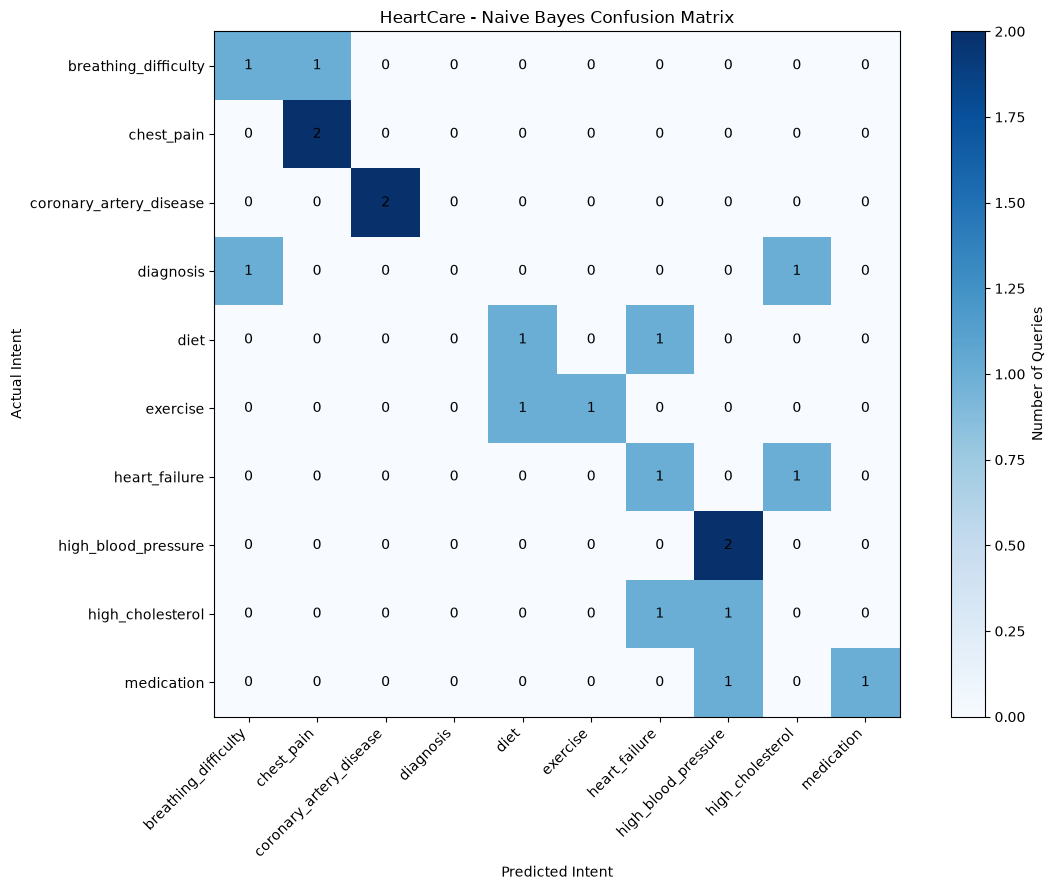

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 9))

plt.imshow(confusion, interpolation='nearest', cmap='Blues')

plt.title("HeartCare - Naive Bayes Confusion Matrix")
plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")

plt.xticks(
    range(len(model.classes)),
    model.classes,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(model.classes)),
    model.classes
)

# Display values inside each cell
for i in range(len(confusion)):
    for j in range(len(confusion[i])):

        plt.text(
            j, i,
            confusion[i][j],
            ha="center",
            va="center"
        )

plt.colorbar(label="Number of Queries")

plt.tight_layout()
plt.show()

### Knowledge base

In [37]:
knowledge_base = {

    "coronary_artery_disease": {
        "title": "Coronary Artery Disease",
        "information": (
            "Coronary artery disease occurs when the arteries supplying "
            "blood to the heart become narrowed or blocked due to plaque "
            "buildup. This can reduce the supply of oxygen-rich blood "
            "to the heart muscle."
        ),
        "causes": [
            "High cholesterol",
            "High blood pressure",
            "Smoking",
            "Diabetes",
            "Unhealthy lifestyle"
        ],
        "prevention": (
            "Maintain a balanced diet, exercise regularly, avoid smoking, "
            "and manage blood pressure and cholesterol."
        )
    },

    "heart_failure": {
        "title": "Heart Failure",
        "information": (
            "Heart failure is a condition in which the heart cannot pump "
            "blood effectively enough to meet the body's needs. It may "
            "cause fluid buildup and reduced blood circulation."
        ),
        "symptoms": [
            "Fatigue",
            "Swelling in legs and ankles",
            "Shortness of breath",
            "Difficulty performing physical activities"
        ],
        "management": (
            "Management may include prescribed medication, lifestyle "
            "changes, regular monitoring and medical supervision."
        )
    },

    "chest_pain": {
        "title": "Chest Pain",
        "information": (
            "Chest pain can occur due to heart-related or non-heart-related "
            "conditions. Possible causes include heart disease, acid reflux, "
            "muscle strain and respiratory problems."
        ),
        "warning_signs": [
            "Pressure or tightness in the chest",
            "Pain spreading to the arm, jaw or back",
            "Sweating",
            "Nausea",
            "Breathing difficulty"
        ],
        "advice": (
            "New, severe or unexplained chest pain requires immediate "
            "medical assessment, particularly when accompanied by other "
            "warning signs."
        )
    },

    "breathing_difficulty": {
        "title": "Breathing Difficulty",
        "information": (
            "Breathing difficulty, also called dyspnea, is the feeling "
            "of not getting enough air. It can be associated with heart "
            "conditions, lung diseases and other medical problems."
        ),
        "possible_causes": [
            "Heart failure",
            "Respiratory conditions",
            "Physical exertion",
            "Other underlying medical conditions"
        ],
        "advice": (
            "Sudden or severe breathing difficulty requires immediate "
            "medical attention."
        )
    },

    "high_blood_pressure": {
        "title": "High Blood Pressure",
        "information": (
            "High blood pressure, also known as hypertension, is a condition "
            "in which the force of blood against artery walls remains "
            "consistently elevated."
        ),
        "risk_factors": [
            "High sodium intake",
            "Physical inactivity",
            "Smoking",
            "Excessive alcohol consumption",
            "Family history"
        ],
        "management": (
            "Blood pressure can be managed through a balanced diet, "
            "physical activity, limiting sodium intake, regular monitoring "
            "and prescribed medication when required."
        )
    },

    "high_cholesterol": {
        "title": "High Cholesterol",
        "information": (
            "Cholesterol is a fatty substance required by the body. "
            "However, high levels of LDL cholesterol can contribute "
            "to plaque buildup in arteries and increase cardiovascular risk."
        ),
        "types": {
            "LDL": "Low-density lipoprotein, commonly called bad cholesterol.",
            "HDL": "High-density lipoprotein, commonly called good cholesterol."
        },
        "management": (
            "A heart-healthy diet, regular exercise, avoiding smoking "
            "and prescribed medication can help manage cholesterol levels."
        )
    },

    "diet": {
        "title": "Heart Healthy Diet",
        "information": (
            "A heart-healthy diet supports cardiovascular health and "
            "helps manage cholesterol and blood pressure."
        ),
        "recommended_foods": [
            "Fresh fruits",
            "Vegetables",
            "Whole grains",
            "Nuts and seeds",
            "Legumes",
            "Fish"
        ],
        "foods_to_limit": [
            "Excessive salt",
            "Processed foods",
            "Foods high in saturated fats",
            "Sugary beverages"
        ],
        "advice": (
            "Follow a balanced diet with appropriate portions and "
            "consult a healthcare professional for individual dietary needs."
        )
    },

    "exercise": {
        "title": "Exercise and Heart Health",
        "information": (
            "Regular physical activity helps improve cardiovascular fitness, "
            "blood circulation and overall heart health."
        ),
        "activities": [
            "Walking",
            "Cycling",
            "Swimming",
            "Light aerobic exercises"
        ],
        "benefits": [
            "Improves cardiovascular fitness",
            "Helps control blood pressure",
            "Supports healthy cholesterol levels",
            "Helps maintain a healthy body weight"
        ],
        "advice": (
            "Adults are generally advised to aim for at least 150 minutes "
            "of moderate-intensity aerobic activity per week, if medically "
            "appropriate."
        )
    },

    "diagnosis": {
        "title": "Heart Disease Diagnosis",
        "information": (
            "Heart conditions can be evaluated using medical history, "
            "physical examination and diagnostic investigations."
        ),
        "tests": {
            "ECG": "Records the electrical activity of the heart.",
            "Echocardiogram": "Uses ultrasound to examine heart structure and function.",
            "Cardiac MRI": "Provides detailed images of heart structures.",
            "Stress Test": "Evaluates heart performance during physical activity.",
            "Blood Tests": "Can measure cholesterol and certain markers of heart damage."
        },
        "advice": (
            "A qualified healthcare professional determines which tests "
            "are appropriate based on symptoms and medical history."
        )
    },

    "medication": {
        "title": "Heart Medication",
        "information": (
            "Heart medications are prescribed to manage cardiovascular "
            "conditions and reduce the risk of complications."
        ),
        "examples": {
            "Beta Blockers": "May reduce heart rate and blood pressure.",
            "Statins": "Help lower LDL cholesterol.",
            "ACE Inhibitors": "Help relax blood vessels and manage blood pressure.",
            "Antiplatelets": "Help reduce platelet aggregation."
        },
        "advice": (
            "Medication should only be taken as prescribed. Do not start, "
            "stop or change medication without consulting a healthcare professional."
        )
    }
}
print("Total Knowledge Categories:", len(knowledge_base))

Total Knowledge Categories: 10


In [38]:
for intent, details in knowledge_base.items():
    print("\nIntent:", intent)
    print("Title:", details["title"])
    print("Information:", details["information"])
    print()


Intent: coronary_artery_disease
Title: Coronary Artery Disease
Information: Coronary artery disease occurs when the arteries supplying blood to the heart become narrowed or blocked due to plaque buildup. This can reduce the supply of oxygen-rich blood to the heart muscle.


Intent: heart_failure
Title: Heart Failure
Information: Heart failure is a condition in which the heart cannot pump blood effectively enough to meet the body's needs. It may cause fluid buildup and reduced blood circulation.


Intent: chest_pain
Title: Chest Pain
Information: Chest pain can occur due to heart-related or non-heart-related conditions. Possible causes include heart disease, acid reflux, muscle strain and respiratory problems.


Intent: breathing_difficulty
Title: Breathing Difficulty
Information: Breathing difficulty, also called dyspnea, is the feeling of not getting enough air. It can be associated with heart conditions, lung diseases and other medical problems.


Intent: high_blood_pressure
Title: 

In [39]:

def retrieve_knowledge(intent):

    if intent in knowledge_base:

        information = knowledge_base[intent]

        response = information["title"] + "\n"
        response += information["information"] + "\n"

        for key, value in information.items():

            if key in ["title", "information", "advice"]:
                continue

            # Skip sections with no information
            if not value:
                continue

            response += "\n" + key.replace("_", " ").title() + ":\n"

            if isinstance(value, dict):

                for sub_key, sub_value in value.items():
                    response += f"- {sub_key}: {sub_value}\n"

            elif isinstance(value, list):

                for item in value:
                    response += f"- {item}\n"

        if information.get("advice"):
            response += "\nAdvice:\n" + information["advice"]

        return response.strip()

    return "Sorry, relevant information is not available."


In [40]:
test_intent = "high_cholesterol"
response = retrieve_knowledge(test_intent)

print(response)

High Cholesterol
Cholesterol is a fatty substance required by the body. However, high levels of LDL cholesterol can contribute to plaque buildup in arteries and increase cardiovascular risk.

Types:
- LDL: Low-density lipoprotein, commonly called bad cholesterol.
- HDL: High-density lipoprotein, commonly called good cholesterol.

Management:


### Rule based Reasoning

In [41]:
emergency_keywords = [
    "severe chest pain",
    "chest pain and sweating",
    "difficulty breathing",
    "cannot breathe",
    "shortness of breath and chest pain",
    "fainting",
    "unconscious",
    "sudden severe chest pain",
    "chest pressure and breathlessness"
]

In [42]:
def detect_emergency(query):

    query = query.lower()

    for keyword in emergency_keywords:

        if keyword in query:
            return True

    return False

In [43]:
def predict_proba(self, vector):
    scores = {}
    for category in self.classes:

        score = math.log(self.priors[category])

        for j, value in enumerate(vector):

            if value > 0:
                score += value * math.log(
                    self.likelihoods[category][j]
                )

        scores[category] = score

    max_score = max(scores.values())

    exp_scores = {
        category: math.exp(score - max_score)
        for category, score in scores.items()
    }

    total = sum(exp_scores.values())

    probabilities = {
        category: value / total
        for category, value in exp_scores.items()
    }

    return probabilities

In [44]:
ConfidenceThreshold = 0.30

In [45]:
def reasoning_engine(query):

    # Rule 1: Emergency detection
    if detect_emergency(query):

        return (
            "EMERGENCY ALERT!\n\n"
            "Your query mentions potentially serious symptoms. "
            "Please seek immediate medical attention. "
            "If you are in India, call 112 for emergency assistance. "
            "Do not delay care while using this assistant."
        )

    # Preprocess user query
    processed = preprocess_text(query)

    # Rule 3: Unsupported or empty query
    if not processed:
        return "Please enter a meaningful heart-health query."

    # Generate TF-IDF vector
    vector = generate_vectors(
        [processed],
        train_vocabulary,
        train_idf
    )

    # Calculate confidence
    probabilities = model.predict_proba(vector[0])

    predicted_intent = max(
        probabilities,
        key=probabilities.get
    )

    confidence = probabilities[predicted_intent]

    # Rule 2: Low-confidence handling
    if confidence < ConfidenceThreshold:
        return (
            "I am not confident enough to understand your query.\n"
            "Please rephrase your question or ask something "
            "related to heart health."
        )

    # Rule 4: Knowledge retrieval
    response = retrieve_knowledge(predicted_intent)

    # Rule 5: Display related information
    return (
        f"Detected Intent: {predicted_intent}\n"
        f"Confidence: {confidence:.2%}\n\n"
        f"{response}"
    )

## Assistant

In [46]:
test_queries = [
    "What is coronary artery disease?",
    "How can I reduce bad cholesterol?",
    "I have severe chest pain and difficulty breathing",
    "Tell me something",
    "What is the weather today?"
]

for query in test_queries:

    print("\nUSER:", query)
    print("\nHEARTCARE:", reasoning_engine(query))


USER: What is coronary artery disease?

HEARTCARE: Detected Intent: coronary_artery_disease
Confidence: 77.51%

Coronary Artery Disease
Coronary artery disease occurs when the arteries supplying blood to the heart become narrowed or blocked due to plaque buildup. This can reduce the supply of oxygen-rich blood to the heart muscle.

Causes:
- High cholesterol
- High blood pressure
- Smoking
- Diabetes
- Unhealthy lifestyle

Prevention:

USER: How can I reduce bad cholesterol?

HEARTCARE: Detected Intent: high_cholesterol
Confidence: 38.29%

High Cholesterol
Cholesterol is a fatty substance required by the body. However, high levels of LDL cholesterol can contribute to plaque buildup in arteries and increase cardiovascular risk.

Types:
- LDL: Low-density lipoprotein, commonly called bad cholesterol.
- HDL: High-density lipoprotein, commonly called good cholesterol.

Management:

USER: I have severe chest pain and difficulty breathing

HEARTCARE: EMERGENCY ALERT!

Your query mentions po

In [47]:
test_cases = {

    "Intent Query": [
        "What causes coronary artery disease?",
        "Why does heart failure occur?",
        "What causes chest pain?",
        "Why do I experience breathlessness?",
        "How can I manage hypertension?",
        "What is LDL cholesterol?",
        "What foods improve heart health?",
        "Is cycling good for the heart?",
        "How does an ECG work?",
        "What are statins used for?"
    ],

    "Different Wording": [
        "How can I keep my cardiovascular system healthy?"
    ],

    "Unsupported Query": [
        "How can I treat kidney stones?"
    ],

    "Low Confidence Query": [
        "Tell me something interesting"
    ],

    "Emergency Query": [
        "I have severe chest pain and cannot breathe"
    ]
}

In [50]:
for category, queries in test_cases.items():

    print("TEST CATEGORY:", category)
    for query in queries:
        print()
        print("User:", query)
        print("Assistant:", reasoning_engine(query))

TEST CATEGORY: Intent Query

User: What causes coronary artery disease?
Assistant: Detected Intent: coronary_artery_disease
Confidence: 57.36%

Coronary Artery Disease
Coronary artery disease occurs when the arteries supplying blood to the heart become narrowed or blocked due to plaque buildup. This can reduce the supply of oxygen-rich blood to the heart muscle.

Causes:
- High cholesterol
- High blood pressure
- Smoking
- Diabetes
- Unhealthy lifestyle

Prevention:

User: Why does heart failure occur?
Assistant: I am not confident enough to understand your query.
Please rephrase your question or ask something related to heart health.

User: What causes chest pain?
Assistant: Detected Intent: chest_pain
Confidence: 63.26%

Chest Pain
Chest pain can occur due to heart-related or non-heart-related conditions. Possible causes include heart disease, acid reflux, muscle strain and respiratory problems.

Warning Signs:
- Pressure or tightness in the chest
- Pain spreading to the arm, jaw or 